# Laboratorio 9 - Deep Learning

- Juan Solís - 23720
- Victor Pérez - 23731
- Diego Flores - 23714
- Nils Muralles - 23727
- Isabella Recinos - 23003

## Task 3

### Task 3.1

Se implementa una U-Net pequeña condicionada por el instante y la clase. La clase 10 representa la condición nula.

In [1]:
import math
import torch
import torch.nn as nn

SEED = 42
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        if dim % 2 != 0:
            raise ValueError("dim debe ser par")
        frequencies = torch.exp(
            torch.arange(0, dim, 2, dtype=torch.float32)
            * (-math.log(10000.0) / dim)
        )
        self.dim = dim
        self.register_buffer("frequencies", frequencies)

    def forward(self, t):
        angles = t.float().unsqueeze(1) * self.frequencies.unsqueeze(0)
        embedding = torch.empty(t.size(0), self.dim, device=t.device)
        embedding[:, 0::2] = torch.sin(angles)
        embedding[:, 1::2] = torch.cos(angles)
        return embedding


class ConditionedBlock(nn.Module):
    def __init__(self, in_channels, out_channels, condition_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_channels)
        self.condition_projection = nn.Linear(condition_dim, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.activation = nn.SiLU()

    def forward(self, x, condition):
        h = self.activation(self.norm1(self.conv1(x)))
        h = h + self.condition_projection(condition)[:, :, None, None]
        h = self.activation(self.norm2(self.conv2(h)))
        return h


class SmallConditionalUNet(nn.Module):
    def __init__(self, condition_dim=64):
        super().__init__()
        self.time_embedding = SinusoidalEmbedding(condition_dim)
        self.time_mlp = nn.Sequential(
            nn.Linear(condition_dim, condition_dim),
            nn.SiLU(),
            nn.Linear(condition_dim, condition_dim),
        )
        self.class_embedding = nn.Embedding(11, condition_dim)

        self.encoder_28 = ConditionedBlock(1, 32, condition_dim)
        self.downsample = nn.Conv2d(32, 64, 4, stride=2, padding=1)
        self.encoder_14 = ConditionedBlock(64, 64, condition_dim)
        self.bottleneck = ConditionedBlock(64, 64, condition_dim)

        self.upsample = nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1)
        self.decoder_28 = ConditionedBlock(64, 32, condition_dim)
        self.output = nn.Conv2d(32, 1, 1)

    def forward(self, x, t, c):
        time_condition = self.time_mlp(self.time_embedding(t))
        class_condition = self.class_embedding(c)
        condition = time_condition + class_condition

        skip = self.encoder_28(x, condition)
        h = self.downsample(skip)
        h = self.encoder_14(h, condition)
        h = self.bottleneck(h, condition)
        h = self.upsample(h)
        h = torch.cat([h, skip], dim=1)
        h = self.decoder_28(h, condition)
        return self.output(h)


model = SmallConditionalUNet().to(device)
x = torch.randn(4, 1, 28, 28, device=device)
t = torch.tensor([1, 250, 500, 1000], device=device)
c = torch.tensor([0, 3, 10, 7], device=device)

model.eval()
with torch.no_grad():
    predicted_noise = model(x, t, c)

parameter_count = sum(p.numel() for p in model.parameters())
assert predicted_noise.shape == x.shape
assert torch.isfinite(predicted_noise).all()
assert parameter_count == 272929

print("Forma de entrada:", tuple(x.shape))
print("Forma de salida:", tuple(predicted_noise.shape))
print("Parametros totales:", parameter_count)
print("Semilla:", SEED, "| device:", device)

Forma de entrada: (4, 1, 28, 28)
Forma de salida: (4, 1, 28, 28)
Parametros totales: 272929
Semilla: 42 | device: cpu


### Task 3.2

Se entrena el modelo para predecir el ruido y se evalúa la pérdida en 10 intervalos de tiempo.

In [2]:
import matplotlib.pyplot as plt
from torchvision import datasets

epochs = 30
batch_size = 128
lr = 2e-4
p_uncond = 0.1
T = 1000
beta_start = 1e-4
beta_end = 0.02

data = datasets.FashionMNIST("data", train=True, download=True)
X = (data.data.float() / 255.0 * 2 - 1).unsqueeze(1)
Y = data.targets
x_train, y_train = X[:-5000].to(device), Y[:-5000].to(device)
x_val, y_val = X[-5000:].to(device), Y[-5000:].to(device)

betas = torch.linspace(beta_start, beta_end, T, device=device)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

def q_sample(x0, t, eps):
    ab = alpha_bar[t - 1].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

print("Entrenamiento:", tuple(x_train.shape))
print("Validacion:", tuple(x_val.shape))

Entrenamiento: (55000, 1, 28, 28)
Validacion: (5000, 1, 28, 28)


Epoca 01/30: perdida = 0.13459


Epoca 02/30: perdida = 0.06598


Epoca 03/30: perdida = 0.05828


Epoca 04/30: perdida = 0.05460


Epoca 05/30: perdida = 0.05198


...

Epoca 26/30: perdida = 0.04264


Epoca 27/30: perdida = 0.04237


Epoca 28/30: perdida = 0.04173


Epoca 29/30: perdida = 0.04233


Epoca 30/30: perdida = 0.04237


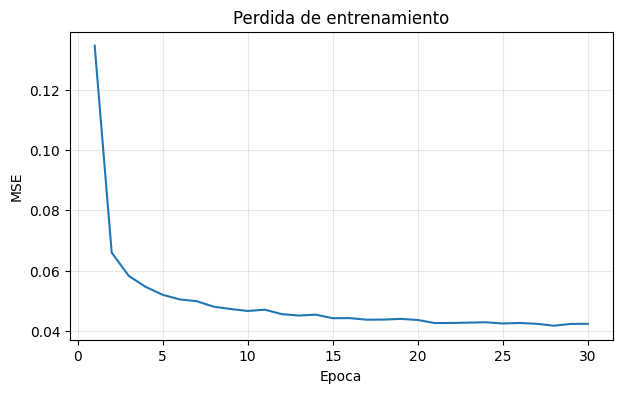

In [3]:
torch.manual_seed(SEED)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
train_losses = []

for epoch in range(epochs):
    model.train()
    permutation = torch.randperm(len(x_train), device=device)
    total_loss = 0.0

    for i in range(0, len(x_train), batch_size):
        indices = permutation[i:i + batch_size]
        x0 = x_train[indices]
        labels = y_train[indices]
        t = torch.randint(1, T + 1, (len(x0),), device=device)
        eps = torch.randn_like(x0)
        xt = q_sample(x0, t, eps)

        condition = labels.clone()
        condition[torch.rand(len(x0), device=device) < p_uncond] = 10
        predicted_eps = model(xt, t, condition)
        loss = torch.mean((eps - predicted_eps) ** 2)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(x0)

    epoch_loss = total_loss / len(x_train)
    assert math.isfinite(epoch_loss)
    train_losses.append(epoch_loss)
    print(f"Epoca {epoch + 1:02d}/{epochs}: perdida = {epoch_loss:.5f}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), train_losses)
plt.xlabel("Epoca")
plt.ylabel("MSE")
plt.title("Perdida de entrenamiento")
plt.grid(alpha=0.3)
plt.show()

t=0001-0100: perdida = 0.22029


t=0101-0200: perdida = 0.08596


t=0201-0300: perdida = 0.04981


t=0301-0400: perdida = 0.02991


t=0401-0500: perdida = 0.01644


t=0501-0600: perdida = 0.00798


t=0601-0700: perdida = 0.00326


t=0701-0800: perdida = 0.00126


t=0801-0900: perdida = 0.00064


t=0901-1000: perdida = 0.00053


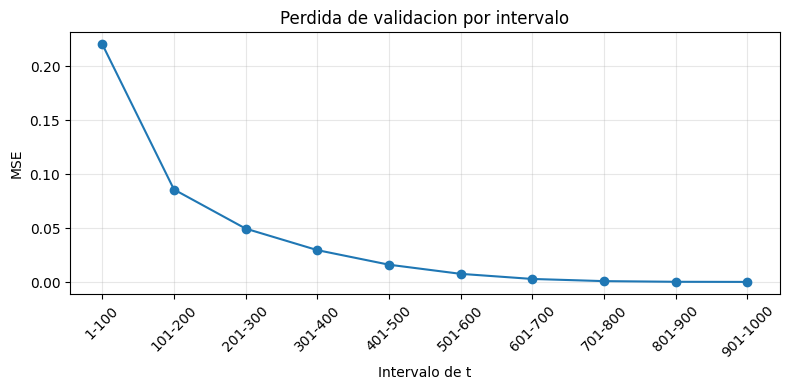

In [4]:
model.eval()
interval_losses = []

with torch.no_grad():
    for interval in range(10):
        squared_error = 0.0
        value_count = 0
        t_start = interval * 100 + 1
        t_end = (interval + 1) * 100 + 1

        for i in range(0, len(x_val), batch_size):
            x0 = x_val[i:i + batch_size]
            labels = y_val[i:i + batch_size]
            t = torch.randint(t_start, t_end, (len(x0),), device=device)
            eps = torch.randn_like(x0)
            xt = q_sample(x0, t, eps)
            predicted_eps = model(xt, t, labels)
            squared_error += torch.sum((eps - predicted_eps) ** 2).item()
            value_count += eps.numel()

        interval_loss = squared_error / value_count
        assert math.isfinite(interval_loss)
        interval_losses.append(interval_loss)
        print(f"t={t_start:04d}-{t_end - 1:04d}: perdida = {interval_loss:.5f}")

assert len(interval_losses) == 10
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), interval_losses, marker="o")
plt.xticks(range(1, 11), [f"{i * 100 + 1}-{(i + 1) * 100}" for i in range(10)], rotation=45)
plt.xlabel("Intervalo de t")
plt.ylabel("MSE")
plt.title("Perdida de validacion por intervalo")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Task 3.3

Se aplica el muestreo ancestral y se generan 10 imágenes por clase.

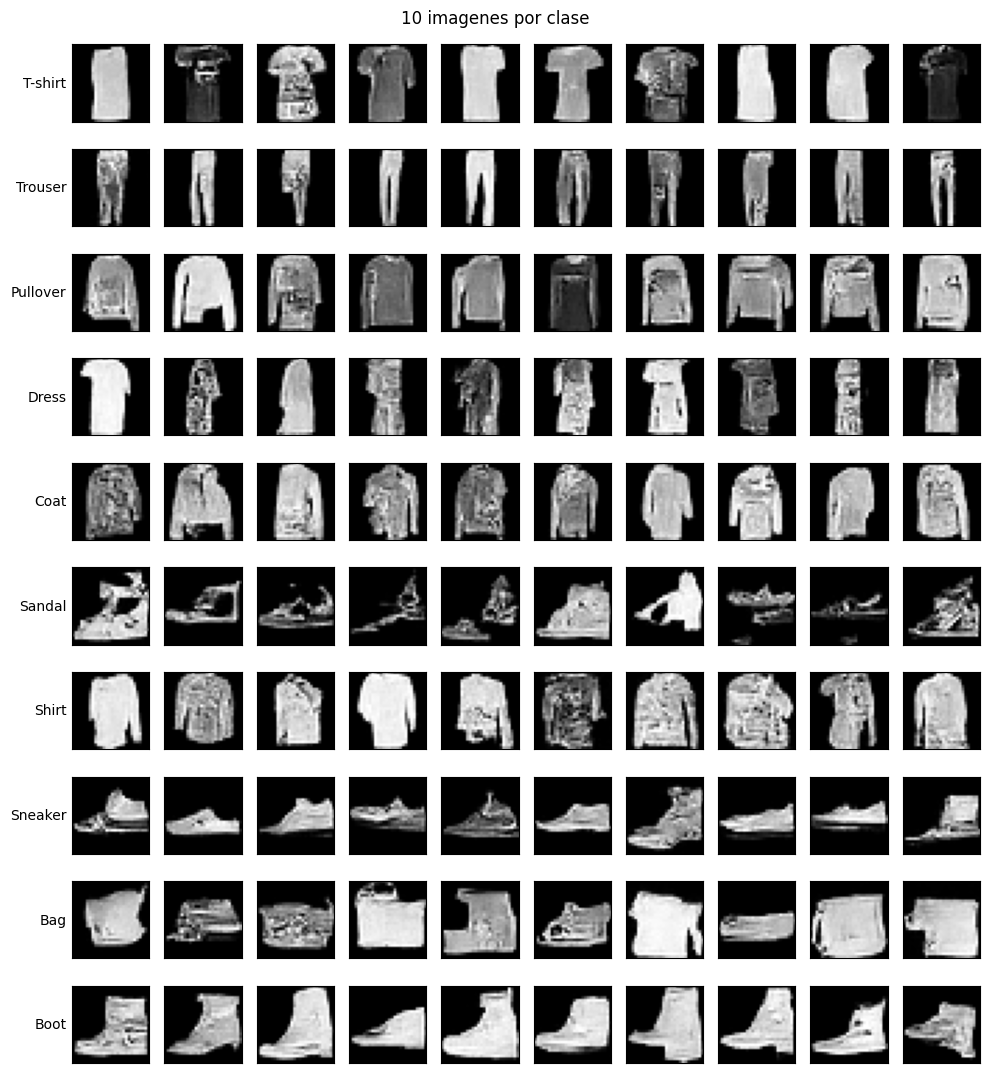

In [5]:
@torch.no_grad()
def ancestral_sample(model, labels):
    model.eval()
    x = torch.randn(len(labels), 1, 28, 28, device=device)

    for step in range(T, 0, -1):
        t = torch.full((len(labels),), step, device=device, dtype=torch.long)
        predicted_eps = model(x, t, labels)
        alpha_t = alphas[step - 1]
        alpha_bar_t = alpha_bar[step - 1]
        mean = (x - (1 - alpha_t) / torch.sqrt(1 - alpha_bar_t) * predicted_eps) / torch.sqrt(alpha_t)

        if step > 1:
            x = mean + torch.sqrt(betas[step - 1]) * torch.randn_like(x)
        else:
            x = mean

    return x.clamp(-1, 1)

class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]
labels = torch.arange(10, device=device).repeat_interleave(10)
torch.manual_seed(SEED)
generated = ancestral_sample(model, labels)

assert generated.shape == (100, 1, 28, 28)
assert torch.isfinite(generated).all()

fig, axs = plt.subplots(10, 10, figsize=(10, 11))
for row in range(10):
    for col in range(10):
        index = row * 10 + col
        axs[row, col].imshow(generated[index, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
        axs[row, col].set_xticks([])
        axs[row, col].set_yticks([])
    axs[row, 0].set_ylabel(class_names[row], rotation=0, ha="right", va="center")
plt.suptitle("10 imagenes por clase")
plt.tight_layout()
plt.show()